In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

# 1. Load dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalisasi nilai piksel (0-255 menjadi 0-1)
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding label target (10 kelas)
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

print('Dimensi data latih:', X_train.shape)
print('Dimensi data uji  :', X_test.shape)


       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/11490434 ━━━━━━━━━━━━━━━━━━━━ 1:17 7us/step

   32768/11490434 ━━━━━━━━━━━━━━━━━━━━ 1:17 7us/step

   49152/11490434 ━━━━━━━━━━━━━━━━━━━━ 1:14 7us/step

   65536/11490434 ━━━━━━━━━━━━━━━━━━━━ 1:21 7us/step

   98304/11490434 ━━━━━━━━━━━━━━━━━━━━ 1:07 6us/step

... (97 outputs left out)

11264000/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step

11378688/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 7s 1us/step


Dimensi data latih: (60000, 28, 28)
Dimensi data uji  : (10000, 28, 28)


In [2]:
tf.random.set_seed(42)
model_1 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model_1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

t0 = time.time()
h1 = model_1.fit(X_train, y_train, epochs=10, batch_size=128, validation_data=(X_test, y_test), verbose=0)
time_1 = time.time() - t0

loss_1, acc_1 = model_1.evaluate(X_test, y_test, verbose=0)
print(f'Model 1 (128-64 ReLU) - Loss: {loss_1:.4f}, Akurasi: {acc_1*100:.2f}%, Waktu: {time_1:.2f}s')


C:\Users\azure\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:36: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model 1 (128-64 ReLU) - Loss: 0.0899, Akurasi: 97.49%, Waktu: 29.93s


In [3]:
tf.random.set_seed(42)
model_2 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model_2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

t0 = time.time()
h2 = model_2.fit(X_train, y_train, epochs=10, batch_size=128, validation_data=(X_test, y_test), verbose=0)
time_2 = time.time() - t0

loss_2, acc_2 = model_2.evaluate(X_test, y_test, verbose=0)
print(f'Model 2 (256-128 ReLU) - Loss: {loss_2:.4f}, Akurasi: {acc_2*100:.2f}%, Waktu: {time_2:.2f}s')


Model 2 (256-128 ReLU) - Loss: 0.1050, Akurasi: 97.37%, Waktu: 36.38s


In [4]:
tf.random.set_seed(42)
model_3 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model_3.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

t0 = time.time()
h3 = model_3.fit(X_train, y_train, epochs=10, batch_size=128, validation_data=(X_test, y_test), verbose=0)
time_3 = time.time() - t0

loss_3, acc_3 = model_3.evaluate(X_test, y_test, verbose=0)
print(f'Model 3 (3 Hidden Layer ReLU) - Loss: {loss_3:.4f}, Akurasi: {acc_3*100:.2f}%, Waktu: {time_3:.2f}s')


Model 3 (3 Hidden Layer ReLU) - Loss: 0.1088, Akurasi: 97.56%, Waktu: 37.18s


In [5]:
tf.random.set_seed(42)
model_4 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='sigmoid'),
    Dense(64, activation='sigmoid'),
    Dense(10, activation='softmax')
])

model_4.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

t0 = time.time()
h4 = model_4.fit(X_train, y_train, epochs=10, batch_size=128, validation_data=(X_test, y_test), verbose=0)
time_4 = time.time() - t0

loss_4, acc_4 = model_4.evaluate(X_test, y_test, verbose=0)
print(f'Model 4 (128-64 Sigmoid) - Loss: {loss_4:.4f}, Akurasi: {acc_4*100:.2f}%, Waktu: {time_4:.2f}s')


Model 4 (128-64 Sigmoid) - Loss: 0.0866, Akurasi: 97.40%, Waktu: 27.40s


                        Arsitektur Model  Loss Uji Akurasi Uji Waktu Latih (s)
0       Model 1 (2 Hidden: 128, 64 ReLU)  0.089857      97.49%           29.93
1      Model 2 (2 Hidden: 256, 128 ReLU)  0.104969      97.37%           36.38
2  Model 3 (3 Hidden: 256, 128, 64 ReLU)  0.108836      97.56%           37.18
3    Model 4 (2 Hidden: 128, 64 Sigmoid)  0.086573      97.40%           27.40


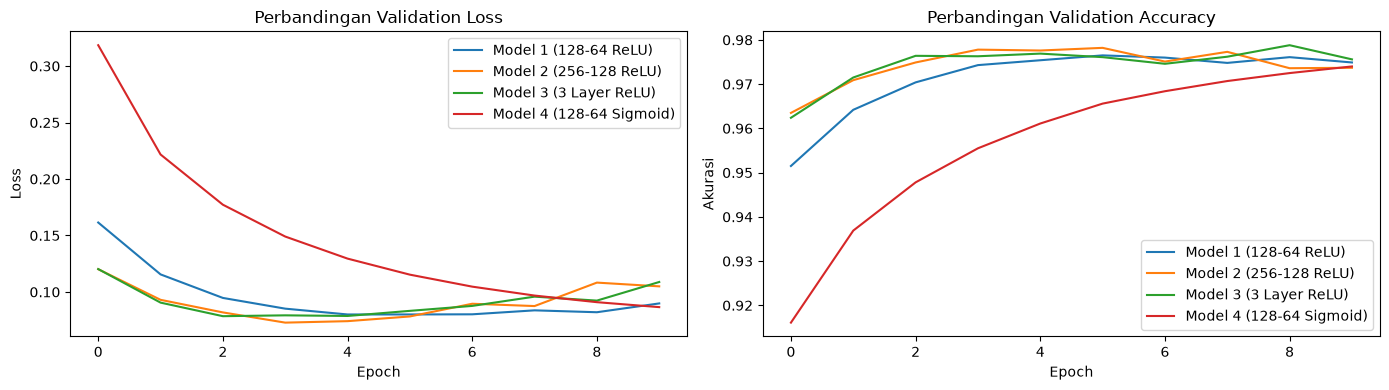

In [6]:
df_tugas = pd.DataFrame({
    'Arsitektur Model': [
        'Model 1 (2 Hidden: 128, 64 ReLU)',
        'Model 2 (2 Hidden: 256, 128 ReLU)',
        'Model 3 (3 Hidden: 256, 128, 64 ReLU)',
        'Model 4 (2 Hidden: 128, 64 Sigmoid)'
    ],
    'Loss Uji': [loss_1, loss_2, loss_3, loss_4],
    'Akurasi Uji': [f'{acc_1*100:.2f}%', f'{acc_2*100:.2f}%', f'{acc_3*100:.2f}%', f'{acc_4*100:.2f}%'],
    'Waktu Latih (s)': [f'{time_1:.2f}', f'{time_2:.2f}', f'{time_3:.2f}', f'{time_4:.2f}']
})
print(df_tugas)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(h1.history['val_loss'], label='Model 1 (128-64 ReLU)')
axes[0].plot(h2.history['val_loss'], label='Model 2 (256-128 ReLU)')
axes[0].plot(h3.history['val_loss'], label='Model 3 (3 Layer ReLU)')
axes[0].plot(h4.history['val_loss'], label='Model 4 (128-64 Sigmoid)')
axes[0].set_title('Perbandingan Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(h1.history['val_accuracy'], label='Model 1 (128-64 ReLU)')
axes[1].plot(h2.history['val_accuracy'], label='Model 2 (256-128 ReLU)')
axes[1].plot(h3.history['val_accuracy'], label='Model 3 (3 Layer ReLU)')
axes[1].plot(h4.history['val_accuracy'], label='Model 4 (128-64 Sigmoid)')
axes[1].set_title('Perbandingan Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Akurasi')
axes[1].legend()

plt.tight_layout()
plt.show()
